In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import train_test_split 
%matplotlib inline

In [2]:
df = pd.read_csv('height-weight.csv')
df.head()

,Weight,Height
0,45,120
1,58,135
2,48,123
3,60,145
4,70,160


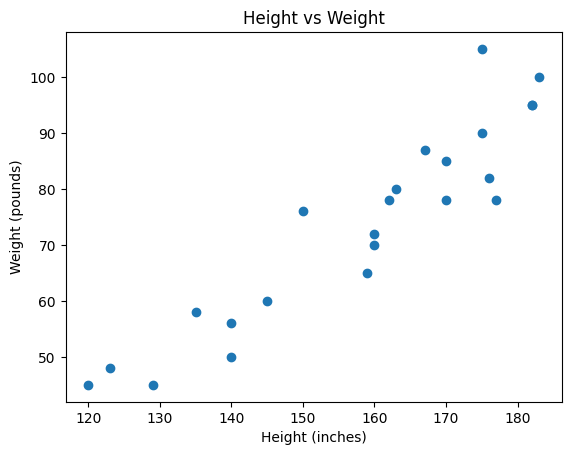

In [3]:
plt.scatter(df['Height'], df['Weight'] )
plt.xlabel('Height (inches)')
plt.ylabel('Weight (pounds)')
plt.title('Height vs Weight')
plt.show()

In [11]:
X = df[['Weight']]
y = df['Height']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

X_train.shape

(18, 1)

## standardize the dataset

In [8]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

In [15]:
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

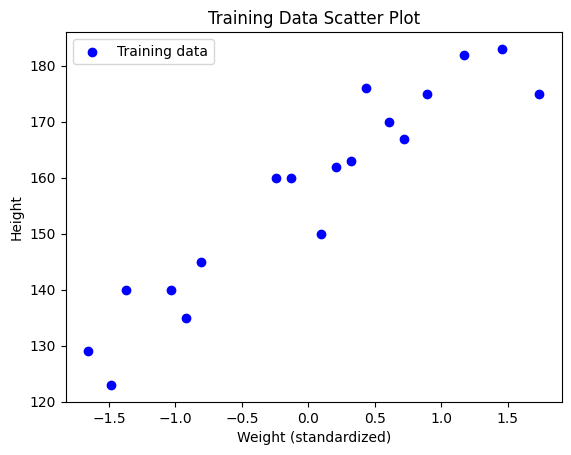

In [16]:
plt.scatter(X_train, y_train, color='blue', label='Training data')
plt.title('Training Data Scatter Plot')
plt.xlabel('Weight (standardized)')
plt.ylabel('Height')
plt.legend()
plt.show()

In [17]:
from sklearn.linear_model import LinearRegression
regressor = LinearRegression()


In [18]:
regressor.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [19]:
print("Coefficients:", regressor.coef_)
print("Intercept:", regressor.intercept_)

Coefficients: [17.03440872]
Intercept: 157.5


C:\Users\Gaurav\AppData\Local\Temp\ipykernel_29732\558911420.py:2: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r" (-> color=(1.0, 0.0, 0.0, 1)). The keyword argument will take precedence.
  plt.plot(X_train, regressor.predict(X_train), 'r', color='red', label='Regression Line')


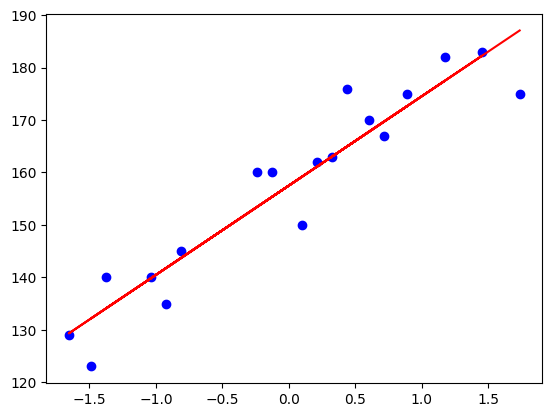

In [25]:
plt.scatter(X_train, y_train, color='blue', label='Training data')
plt.plot(X_train, regressor.predict(X_train), 'r', color='red', label='Regression Line')

## Prediction of Test Data

C:\Users\Gaurav\AppData\Local\Temp\ipykernel_29732\779800188.py:3: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r" (-> color=(1.0, 0.0, 0.0, 1)). The keyword argument will take precedence.
  plt.plot(X_test, y_pred, 'r', color='red', label='Regression Line')


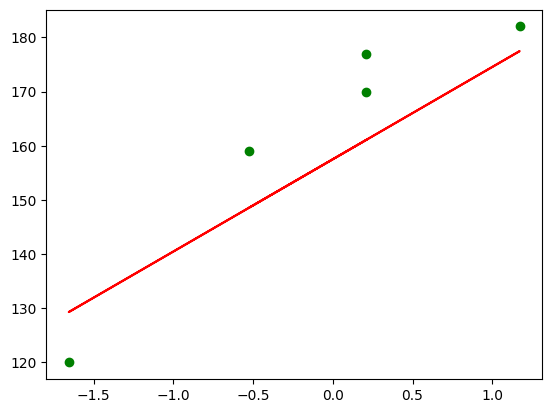

In [26]:
y_pred = regressor.predict(X_test)
plt.scatter(X_test, y_test, color='green', label='Test data')
plt.plot(X_test, y_pred, 'r', color='red', label='Regression Line')

## Performance Metrics

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error,r2_score

Mean Squared Error: 109.77592599051664
Mean Absolute Error: 9.822657814519232
Root Mean Squared Error: 10.477400726827081
R-squared: 0.776986986042344
Adjusted R-squared: 0.7026493147231252


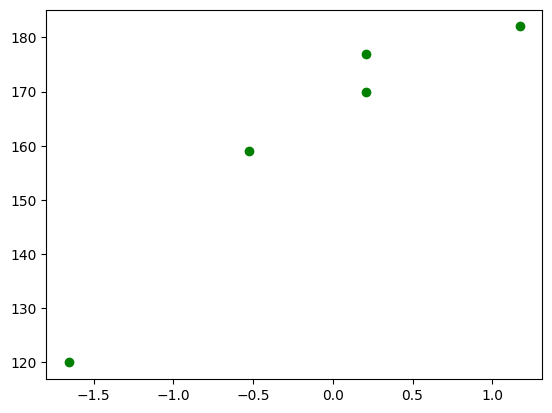

In [29]:
mse= mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("Mean Squared Error:", mse)
print("Mean Absolute Error:", mae)
print("Root Mean Squared Error:", rmse)
print("R-squared:", r2_score(y_test, y_pred))
print("Adjusted R-squared:", 1 - (1 - r2_score(y_test, y_pred)) * (len(y_test) - 1) / (len(y_test) - X_test.shape[1] - 1))

plt.scatter(X_test, y_test, color='green', label='Test data')

In [30]:
regressor

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [37]:
scaled_weight = scaler.transform([[80]])  # Example weight
predicted_height = regressor.predict([scaled_weight[0]])
print(f"Predicted Height for 80 pounds: {predicted_height} inches")

Predicted Height for 80 pounds: [1520.25269753] inches


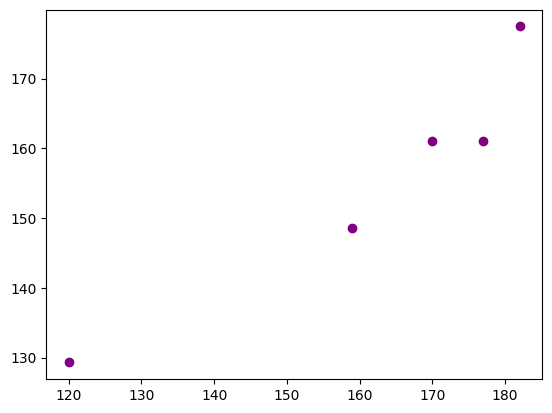

In [39]:
plt.scatter(y_test, y_pred, color='purple')

## Residuals

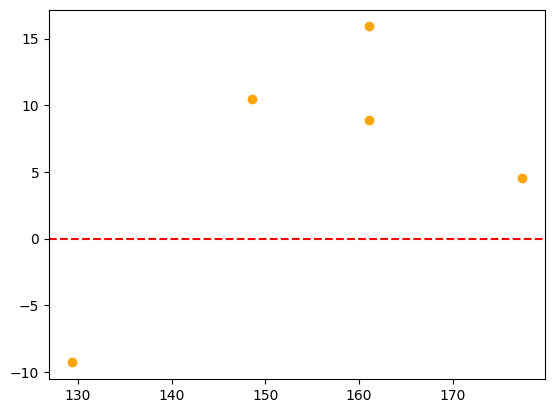

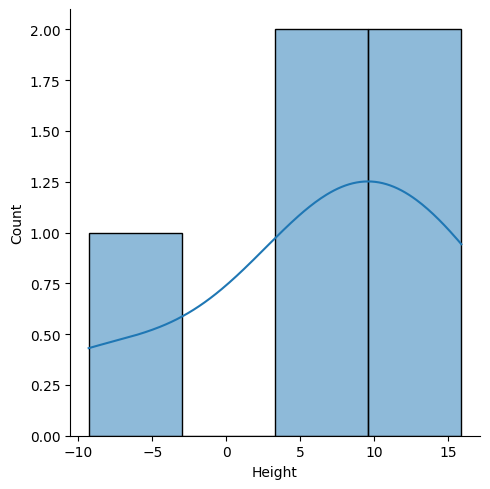

In [42]:
residuals = y_test - y_pred
residuals
plt.scatter(y_pred, residuals, color='orange')
plt.axhline(0, color='red', linestyle='--')
sns.displot(residuals, kde=True)